<a href="https://colab.research.google.com/github/aliturab99/Islamabad_House_price_prediction_ML_Project/blob/main/Zameen_com_Islamabad_Properties_Data_Science_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [9]:
df = pd.read_csv("Zameen.com Islamabad Scraped Data - Sheet1.csv")

In [10]:
df.shape

(14775, 9)

In [11]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 14775 entries, 0 to 14774
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   listing_id  14740 non-null  float64
 1   title       14775 non-null  str    
 2   price_text  14775 non-null  str    
 3   price_pkr   14775 non-null  int64  
 4   location    14775 non-null  str    
 5   area_text   14775 non-null  str    
 6   area_marla  14775 non-null  float64
 7   beds        13868 non-null  float64
 8   baths       13735 non-null  float64
dtypes: float64(4), int64(1), str(4)
memory usage: 1.0 MB


In [12]:
df.isnull().sum()

listing_id      35
title            0
price_text       0
price_pkr        0
location         0
area_text        0
area_marla       0
beds           907
baths         1040
dtype: int64

In [13]:
df.describe()

,listing_id,price_pkr,area_marla,beds,baths
count,1.474000e+04,1.477500e+04,14775.000000,13868.000000,13735.000000
mean,5.410078e+07,9.304380e+07,15.953861,4.453057,4.555661
std,1.590959e+06,1.698869e+08,47.993253,1.983534,1.806038
min,1.745226e+07,8.000000e+04,0.900000,1.000000,1.000000
25%,5.411223e+07,2.500000e+07,5.000000,3.000000,3.000000
50%,5.460245e+07,4.450000e+07,8.000000,5.000000,5.000000
75%,5.477557e+07,9.250000e+07,14.400000,6.000000,6.000000
max,5.487768e+07,4.000000e+09,1760.000000,11.000000,10.000000


In [14]:
df.head()

,listing_id,title,price_text,price_pkr,location,area_text,area_marla,beds,baths
0,54844773.0,House At Prime Location,5.5 Crore,55000000,"D-12/1, D-12",4 Marla,4.0,3.0,5.0
1,54852451.0,Luxury 3-Bedroom Apartment For Sale In Warda H...,5.15 Crore,51500000,"Warda Hamna Residencia, G-11 Markaz",8.7 Marla,8.7,3.0,3.0
2,52696760.0,One kanal Beautiful luxurious FULL FURNISHED H...,10.9 Crore,109000000,"DHA Defence Phase 2, DHA Defence",1 Kanal,20.0,5.0,6.0
3,54793832.0,1 Kanal Luxury House Most Beautiful Prime Loca...,11.9 Crore,119000000,"DHA Defence Phase 2, DHA Defence",1 Kanal,20.0,6.0,6.0
4,54798682.0,Investor Price 1 Kanal Elegant House For Sale ...,7.9 Crore,79000000,"DHA Defence Phase 3, DHA Defence",1 Kanal,20.0,5.0,6.0


In [15]:
df.isnull().sum()

listing_id      35
title            0
price_text       0
price_pkr        0
location         0
area_text        0
area_marla       0
beds           907
baths         1040
dtype: int64

In [16]:
df1 = df.drop(columns=["listing_id", "title", "price_text", "area_text"])

In [17]:
df1.isnull().sum()

price_pkr        0
location         0
area_marla       0
beds           907
baths         1040
dtype: int64

In [18]:
df2 = df1.dropna()

In [19]:
df2

,price_pkr,location,area_marla,beds,baths
0,55000000,"D-12/1, D-12",4.0,3.0,5.0
1,51500000,"Warda Hamna Residencia, G-11 Markaz",8.7,3.0,3.0
2,109000000,"DHA Defence Phase 2, DHA Defence",20.0,5.0,6.0
3,119000000,"DHA Defence Phase 2, DHA Defence",20.0,6.0,6.0
4,79000000,"DHA Defence Phase 3, DHA Defence",20.0,5.0,6.0
...,...,...,...,...,...
14770,7500000,"Taramrri, Islamabad",4.0,3.0,2.0
14771,15500000,"Faisal Hills - Block A, Faisal Hills",5.0,3.0,4.0
14772,17000000,"PHAF Officers Residencia, Kuri Road",4.4,3.0,2.0
14773,82500000,"Margalla Town Phase 2, Margalla Town",8.0,7.0,6.0


In [20]:
df2.duplicated().sum()

np.int64(2763)

In [21]:
df3 = df2.drop_duplicates()

In [22]:
display(df3.shape)
display(df3.duplicated().sum())
display(df3.isnull().sum())

(10733, 5)

np.int64(0)

price_pkr     0
location      0
area_marla    0
beds          0
baths         0
dtype: int64

In [23]:
df3.head()

,price_pkr,location,area_marla,beds,baths
0,55000000,"D-12/1, D-12",4.0,3.0,5.0
1,51500000,"Warda Hamna Residencia, G-11 Markaz",8.7,3.0,3.0
2,109000000,"DHA Defence Phase 2, DHA Defence",20.0,5.0,6.0
3,119000000,"DHA Defence Phase 2, DHA Defence",20.0,6.0,6.0
4,79000000,"DHA Defence Phase 3, DHA Defence",20.0,5.0,6.0


In [24]:
df3["sqrt_ft"] = df["area_marla"] * 272.251
df3.head()

,price_pkr,location,area_marla,beds,baths,sqrt_ft
0,55000000,"D-12/1, D-12",4.0,3.0,5.0,1089.0040
1,51500000,"Warda Hamna Residencia, G-11 Markaz",8.7,3.0,3.0,2368.5837
2,109000000,"DHA Defence Phase 2, DHA Defence",20.0,5.0,6.0,5445.0200
3,119000000,"DHA Defence Phase 2, DHA Defence",20.0,6.0,6.0,5445.0200
4,79000000,"DHA Defence Phase 3, DHA Defence",20.0,5.0,6.0,5445.0200


In [25]:
df3["price_per_sqrt_ft"] = df3["price_pkr"] / df3["sqrt_ft"]
df3["price_per_marla"] = df3["price_pkr"] / df3["area_marla"]

In [26]:
df3.head()

,price_pkr,location,area_marla,beds,baths,sqrt_ft,price_per_sqrt_ft,price_per_marla
0,55000000,"D-12/1, D-12",4.0,3.0,5.0,1089.0040,50504.864996,1.375000e+07
1,51500000,"Warda Hamna Residencia, G-11 Markaz",8.7,3.0,3.0,2368.5837,21742.951284,5.919540e+06
2,109000000,"DHA Defence Phase 2, DHA Defence",20.0,5.0,6.0,5445.0200,20018.291944,5.450000e+06
3,119000000,"DHA Defence Phase 2, DHA Defence",20.0,6.0,6.0,5445.0200,21854.832489,5.950000e+06
4,79000000,"DHA Defence Phase 3, DHA Defence",20.0,5.0,6.0,5445.0200,14508.670308,3.950000e+06


In [27]:
df4 = df3.copy()

In [28]:
def correctLocationNames(location):
  return location.strip().split(", ")[0].split("/")[0]

In [29]:
df4["location"] = df4["location"].apply(correctLocationNames)
len(df.location.unique())

666

In [30]:
df4.head()

,price_pkr,location,area_marla,beds,baths,sqrt_ft,price_per_sqrt_ft,price_per_marla
0,55000000,D-12,4.0,3.0,5.0,1089.0040,50504.864996,1.375000e+07
1,51500000,Warda Hamna Residencia,8.7,3.0,3.0,2368.5837,21742.951284,5.919540e+06
2,109000000,DHA Defence Phase 2,20.0,5.0,6.0,5445.0200,20018.291944,5.450000e+06
3,119000000,DHA Defence Phase 2,20.0,6.0,6.0,5445.0200,21854.832489,5.950000e+06
4,79000000,DHA Defence Phase 3,20.0,5.0,6.0,5445.0200,14508.670308,3.950000e+06


In [31]:
locations_stats = df4.groupby("location")["location"].agg("count").sort_values(ascending=False)
locations_stats

location
DHA Defence Phase 2     451
G-13                    390
Bani Gala               356
B-17                    282
D-12                    273
                       ... 
Aryan Enclave             1
The Palazzo               1
Askari Heights            1
Top City 1 - Block I      1
Tower 45                  1
Name: location, Length: 533, dtype: int64

In [32]:
locations_stats_less_10 = locations_stats[locations_stats < 10]
locations_stats_less_10

location
Ghauri Town                  9
Soan Garden - Block D        9
Thanda Pani                  9
Capital Heights              9
Naval Anchorage - Block F    9
                            ..
Aryan Enclave                1
The Palazzo                  1
Askari Heights               1
Top City 1 - Block I         1
Tower 45                     1
Name: location, Length: 347, dtype: int64

In [33]:
df4["location"] = df4["location"].apply(lambda x: "other" if x in locations_stats_less_10 else x )

In [34]:
len(df4["location"].unique())

187

In [35]:
df5 = df4.copy()

In [36]:
df5.head()

,price_pkr,location,area_marla,beds,baths,sqrt_ft,price_per_sqrt_ft,price_per_marla
0,55000000,D-12,4.0,3.0,5.0,1089.0040,50504.864996,1.375000e+07
1,51500000,Warda Hamna Residencia,8.7,3.0,3.0,2368.5837,21742.951284,5.919540e+06
2,109000000,DHA Defence Phase 2,20.0,5.0,6.0,5445.0200,20018.291944,5.450000e+06
3,119000000,DHA Defence Phase 2,20.0,6.0,6.0,5445.0200,21854.832489,5.950000e+06
4,79000000,DHA Defence Phase 3,20.0,5.0,6.0,5445.0200,14508.670308,3.950000e+06


In [37]:
df5.shape

(10733, 8)

In [38]:
df5 = df5[df5["sqrt_ft"]/df5["beds"] > 250]

In [39]:
df5.shape

df6 = df5.copy()

In [40]:
df6.describe()

,price_pkr,area_marla,beds,baths,sqrt_ft,price_per_sqrt_ft,price_per_marla
count,1.053200e+04,10532.000000,10532.000000,10532.000000,10532.000000,10532.000000,1.053200e+04
mean,9.058563e+07,15.814062,4.372104,4.548994,4305.394168,21711.244550,5.910908e+06
std,1.619241e+08,48.222404,2.010246,1.788284,13128.597594,13162.215907,3.583426e+06
min,8.000000e+04,1.000000,1.000000,1.000000,272.251000,29.384649,8.000000e+03
25%,2.500000e+07,5.000000,3.000000,3.000000,1361.255000,12731.161423,3.466071e+06
50%,4.300000e+07,8.000000,4.000000,5.000000,2178.008000,18365.405453,5.000000e+06
75%,8.800000e+07,14.000000,6.000000,6.000000,3811.514000,27180.800071,7.400000e+06
max,4.000000e+09,1760.000000,11.000000,10.000000,479161.760000,183654.054531,5.000000e+07


In [41]:
q1 = df6["price_per_sqrt_ft"].quantile(0.25)
q3 = df6["price_per_sqrt_ft"].quantile(0.75)
iqr = q3 - q1

lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

print("Lower Bound", lower_bound)
print("Upper Bound", upper_bound)

lower_bound = 0 if lower_bound < 0 else lower_bound

print("Lower Bound", lower_bound)
print("Upper Bound", upper_bound)

Lower Bound -8943.29654830076
Upper Bound 48855.25804181751
Lower Bound 0
Upper Bound 48855.25804181751


In [42]:
df6 = df6[(df6["price_per_sqrt_ft"] > lower_bound) & (df6["price_per_sqrt_ft"] < upper_bound)]

In [43]:
display(df6.shape)
display(df6.describe())

(10099, 8)

,price_pkr,area_marla,beds,baths,sqrt_ft,price_per_sqrt_ft,price_per_marla
count,1.009900e+04,10099.000000,10099.000000,10099.000000,10099.000000,10099.000000,1.009900e+04
mean,7.505624e+07,15.392346,4.316467,4.509159,4190.581530,19995.279810,5.443735e+06
std,1.161424e+08,49.011147,1.981359,1.787478,13343.333762,10000.664221,2.722691e+06
min,8.000000e+04,1.000000,1.000000,1.000000,272.251000,29.384649,8.000000e+03
25%,2.400000e+07,5.000000,3.000000,3.000000,1361.255000,12383.530534,3.371429e+06
50%,4.200000e+07,8.000000,4.000000,5.000000,2178.008000,18234.223986,4.964286e+06
75%,8.000000e+07,14.000000,6.000000,6.000000,3811.514000,25252.432498,6.875000e+06
max,2.100000e+09,1760.000000,11.000000,10.000000,479161.760000,48724.545080,1.326531e+07


In [44]:
def remove_pps_outliers(df):
  df_out = pd.DataFrame()
  for key, subdf in df.groupby("location"):
    m = np.mean(subdf["price_per_sqrt_ft"])
    st = np.std(subdf["price_per_sqrt_ft"])
    reduced_df = subdf[(subdf["price_per_sqrt_ft"] > (m - st)) & (subdf["price_per_sqrt_ft"] <= (m + st))]
    df_out = pd.concat([df_out, reduced_df], ignore_index=True)
  return df_out

df7 = remove_pps_outliers(df6)

In [45]:
df7.describe()

,price_pkr,area_marla,beds,baths,sqrt_ft,price_per_sqrt_ft,price_per_marla
count,7.081000e+03,7081.000000,7081.000000,7081.000000,7081.000000,7081.000000,7.081000e+03
mean,7.417604e+07,14.329657,4.448242,4.673916,3901.263401,20094.772709,5.470822e+06
std,1.087494e+08,36.638069,1.907141,1.723552,9974.750967,9006.727710,2.452091e+06
min,2.800000e+06,1.100000,1.000000,1.000000,299.476100,2479.329736,6.750000e+05
25%,2.600000e+07,5.500000,3.000000,3.000000,1497.380500,13595.170270,3.701299e+06
50%,4.250000e+07,8.000000,5.000000,5.000000,2178.008000,18365.405453,5.000000e+06
75%,8.250000e+07,14.000000,6.000000,6.000000,3811.514000,24334.162225,6.625000e+06
max,1.750000e+09,800.000000,11.000000,10.000000,217800.800000,47225.328308,1.285714e+07


In [46]:
display(df6.shape)
display(df7.shape)

(10099, 8)

(7081, 8)

In [47]:
import matplotlib

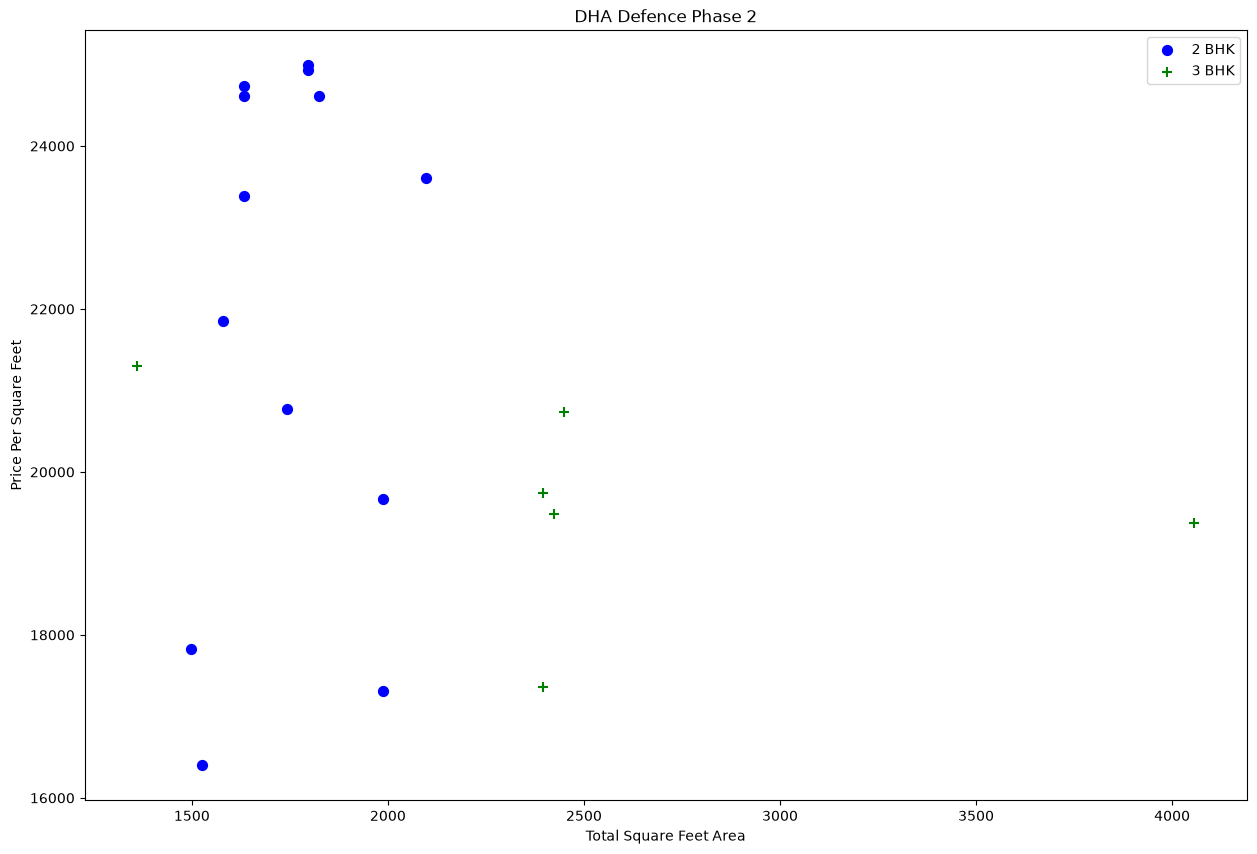

In [48]:
def plot_scatter_chart(df, location):
  bhk2 = df[(df["location"] == location) & (df["beds"] == 2)]
  bhk3 = df[(df["location"] == location) & (df["beds"] == 3)]
  matplotlib.rcParams["figure.figsize"] = (15, 10)
  plt.scatter(bhk2["sqrt_ft"], bhk2["price_per_sqrt_ft"], color="blue", label="2 BHK", s=50)
  plt.scatter(bhk3["sqrt_ft"], bhk3["price_per_sqrt_ft"], marker="+", color="green", label="3 BHK", s=50)
  plt.xlabel("Total Square Feet Area")
  plt.ylabel("Price Per Square Feet")
  plt.title(location)
  plt.legend()

plot_scatter_chart(df7, "DHA Defence Phase 2")

In [49]:
df7.head()

,price_pkr,location,area_marla,beds,baths,sqrt_ft,price_per_sqrt_ft,price_per_marla
0,45000000,11 Central Apartments,6.9,2.0,2.0,1878.5319,23954.876678,6.521739e+06
1,37500000,11 Central Apartments,5.8,2.0,2.0,1579.0558,23748.369120,6.465517e+06
2,45000000,11 Central Apartments,6.8,2.0,2.0,1851.3068,24307.154276,6.617647e+06
3,55000000,11 Central Apartments,8.9,3.0,4.0,2423.0339,22698.815728,6.179775e+06
4,50000000,11 Central Apartments,7.8,3.0,3.0,2123.5578,23545.391606,6.410256e+06


In [50]:
df8 = df7[df7.baths < df7.beds+2]

In [51]:
df8.shape

(6628, 8)

In [52]:
df8 = df8.drop(columns=["sqrt_ft", "price_per_sqrt_ft", "price_per_marla"])

In [53]:
df8.shape

(6628, 5)

In [54]:
df9 = pd.get_dummies(df8, drop_first=True, columns=["location"])

In [55]:
df9.head()

,price_pkr,area_marla,beds,baths,location_Airport Green Garden - Block A,location_Al-Ghurair Giga,location_Askari Heights 4,location_Askari Heights 5,location_Askari Tower 1,location_Askari Tower 2,...,location_Top City 1 - Block C,location_Top City 1 - Block D,location_Top City 1 - Kanwar Moiz Block,location_Veranda Executive,location_Warda Hamna Residencia,location_Warda Hamna Residencia 3,location_Zaraj Housing Scheme,location_Zarkon Heights,location_Zeta-1 Mall,location_other
0,45000000,6.9,2.0,2.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
1,37500000,5.8,2.0,2.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
2,45000000,6.8,2.0,2.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
3,55000000,8.9,3.0,4.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False
4,50000000,7.8,3.0,3.0,False,False,False,False,False,False,...,False,False,False,False,False,False,False,False,False,False


In [56]:
X = df9.drop(columns=["price_pkr"])
y = df9["price_pkr"]

In [57]:
display(X.shape)
display(y.shape)

(6628, 189)

(6628,)

In [58]:
from sklearn.model_selection import train_test_split

In [59]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [60]:
from sklearn.linear_model import LinearRegression

In [61]:
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)
lr_model.score(X_test, y_test)

0.8673175056661446

In [62]:
from sklearn.model_selection import ShuffleSplit, cross_val_score

cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=0)

cross_val_score(LinearRegression(), X, y, cv=cv)

array([0.89900531, 0.88264695, 0.86467529, 0.91228164, 0.92711789])

In [63]:
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import Lasso
from sklearn.tree import DecisionTreeRegressor


In [64]:
def find_best_model_using_gridsearchcv(X, y):
  algos = {
      "linear_regression": {
          "model": LinearRegression(),
          "params": {
              "fit_intercept": [True, False]
          }
      },
      "Lasso": {
          "model": Lasso(),
          "params": {
              "alpha": [1, 2],
              "selection": ["random", "cyclic"]
          }
      },
      "decision_tree": {
          "model": DecisionTreeRegressor(),
          "params": {
              "criterion": ["squared_error", "friedman_mse"],
              "splitter": ["best", "random"]
          }
      }
  }

  scores = []

  cv = ShuffleSplit(n_splits=5, test_size=0.2, random_state=0)

  for algo_name, config in algos.items():
    gs = GridSearchCV(config["model"], config["params"], cv=cv, return_train_score=False)
    gs.fit(X, y)
    scores.append({
        "model": algo_name,
        "best_score": gs.best_score_,
        "best_params": gs.best_params_
    })

  return pd.DataFrame(scores, columns=["model", "best_score", "best_params"])

In [65]:
find_best_model_using_gridsearchcv(X, y)

/Volumes/Coding Work Place/Islamabad_House_price_prediction_ML_Project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.439128e+18, tolerance: 6.131e+15
  model = cd_fast.enet_coordinate_descent(
/Volumes/Coding Work Place/Islamabad_House_price_prediction_ML_Project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 3.613100e+18, tolerance: 6.697e+15
  model = cd_fast.enet_coordinate_descent(
/Volumes/Coding Work Place/Islamabad_House_price_prediction_ML_Project/.venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:842: Convergen

,model,best_score,best_params
0,linear_regression,0.897145,{'fit_intercept': True}
1,Lasso,0.897141,"{'alpha': 1, 'selection': 'random'}"
2,decision_tree,0.912690,"{'criterion': 'squared_error', 'splitter': 'be..."


In [66]:
decision_tree_model = DecisionTreeRegressor(criterion="squared_error", splitter="random")
decision_tree_model.fit(X_train, y_train)
decision_tree_model.score(X_test, y_test)

0.9043679480839995

In [67]:
def predict_house_price(location, marla, rooms, bath):
  # Since pd.get_dummies was used, the column names are prefixed with 'location_'
  column_name = f"location_{location}"

  if column_name in X.columns:
    loc_index = np.where(X.columns == column_name)[0][0]
  elif "location_other" in X.columns:
    # Fallback to 'other' if the specific location is not in dummy columns
    loc_index = np.where(X.columns == "location_other")[0][0]
  else:
    loc_index = -1

  x = np.zeros(len(X.columns))
  x[0] = marla
  x[1] = rooms
  x[2] = bath

  if loc_index >= 0:
    x[loc_index] = 1

  return decision_tree_model.predict([x])[0]

In [68]:
int(predict_house_price("DHA", 2, 1, 1))

/Volumes/Coding Work Place/Islamabad_House_price_prediction_ML_Project/.venv/lib/python3.13/site-packages/sklearn/utils/validation.py:2830: UserWarning: X does not have valid feature names, but DecisionTreeRegressor was fitted with feature names
  warnings.warn(


6566666

In [69]:
import pickle

with open("./model.pkl", "wb") as f:
    pickle.dump(decision_tree_model, f)